# Controle por antecipação
**Medir a perturbação para agir junto com ela.**

O PI espera aparecer um erro. A antecipação usa uma informação extra: a mudança na alimentação.
Aqui vamos comparar as duas respostas sem trocar o PI. Execute as células em ordem;
no fim, solte os controles para atualizar o gráfico. A teoria e as bibliotecas estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/02_antecipacao/README.md).

## O processo
A alimentação de gás cai. Abrir o reciclo ajuda a manter a vazão no compressor.
São dois caminhos até a mesma saída: alimentação → vazão e válvula → vazão.

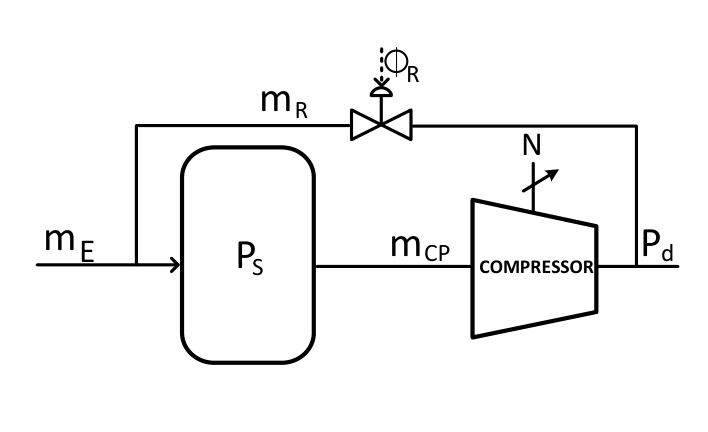

Usaremos **desvios normalizados** e tempo em **u.t.**; zero significa a condição inicial.
É um modelo linear local, não uma simulação completa da proteção antissurge.

In [1]:
%pip -q install control==0.10.2 ipywidgets scipy matplotlib
import numpy as np
import control as controle
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.optimize import least_squares
from IPython.display import display

plt.style.use('default')
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

## Os modelos
$u$: alteração da válvula; $d$: alteração da alimentação; $y$: desvio da vazão.

$$y=G_u u+G_d d,\quad
G_u=\frac{0{,}3211s+0{,}1927}{s^2+0{,}6s+0{,}16},\quad
G_d=\frac{0{,}3092s+0{,}08813}{s^2+0{,}672s+0{,}1764}.$$

In [2]:
s = controle.tf('s')
canal_acao = (0.3211*s + 0.1927) / (s**2 + 0.6*s + 0.16)
canal_perturbacao = (0.3092*s + 0.08813) / (s**2 + 0.672*s + 0.1764)

def responder(modelo, tempo, entrada):
    return np.asarray(controle.forced_response(modelo, tempo, entrada).outputs)

## Identificar com uma medição imperfeita
Faço um degrau pequeno na válvula, mantendo a alimentação constante.
A medição recebe ruído gaussiano. Ajusto apenas $K$ e $\tau$ em
$\widehat G_u=K/(\tau s+1)$: uma aproximação simples para sintonizar o PI.

In [3]:
tempo_ensaio = np.arange(0, 40.05, 0.05)
entrada_ensaio = 0.2 * (tempo_ensaio >= 2)
saida_ensaio = responder(canal_acao, tempo_ensaio, entrada_ensaio)
desvio_ruido = 0.004  # Aqui altero a intensidade do ruído da medição.
gerador = np.random.default_rng(12)  # Mesma semente para repetir o ensaio.
medicao_ensaio = saida_ensaio + gerador.normal(0, desvio_ruido, len(tempo_ensaio))

def prever_degrau(parametros):
    ganho, constante_tempo = parametros
    tempo_desde_degrau = np.maximum(tempo_ensaio - 2, 0)
    return 0.2 * ganho * (1 - np.exp(-tempo_desde_degrau / constante_tempo))

In [4]:
ajuste = least_squares(
    lambda parametros: prever_degrau(parametros) - medicao_ensaio,
    x0=[1.2, 2.1], bounds=([0.1, 0.05], [3, 20])
)
ganho_estimado, tempo_estimado = ajuste.x
modelo_estimado = ganho_estimado / (tempo_estimado*s + 1)
print(f'K estimado = {ganho_estimado:.3f}; tau estimado = {tempo_estimado:.3f} u.t.')

K estimado = 1.221; tau estimado = 2.462 u.t.


## Validar sem mexer no ajuste
Agora faço **outro ensaio**, com subida e descida e um novo ruído.
O modelo usa os mesmos parâmetros. A diferença entre as curvas mostra
o que a aproximação de primeira ordem deixou de representar.

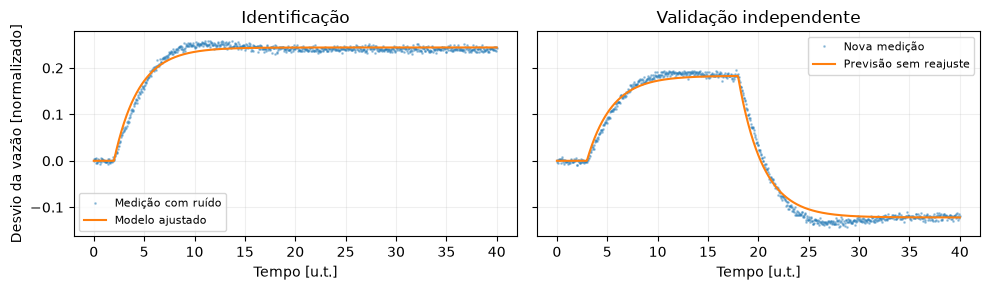

RMSE da validação: 0.0112 (saída normalizada)


In [5]:
entrada_validacao = 0.15*(tempo_ensaio >= 3) - 0.25*(tempo_ensaio >= 18)
saida_validacao = responder(canal_acao, tempo_ensaio, entrada_validacao)
gerador_validacao = np.random.default_rng(31)
medicao_validacao = saida_validacao + gerador_validacao.normal(
    0, desvio_ruido, len(tempo_ensaio))
previsao_validacao = responder(modelo_estimado, tempo_ensaio, entrada_validacao)
erro_validacao = medicao_validacao - previsao_validacao
rmse_validacao = np.sqrt(np.mean(erro_validacao**2))
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
eixos[0].plot(tempo_ensaio, medicao_ensaio, '.', ms=2, alpha=0.35, label='Medição com ruído')
eixos[0].plot(tempo_ensaio, prever_degrau(ajuste.x), label='Modelo ajustado')
eixos[1].plot(tempo_ensaio, medicao_validacao, '.', ms=2, alpha=0.35, label='Nova medição')
eixos[1].plot(tempo_ensaio, previsao_validacao, label='Previsão sem reajuste')
for eixo, titulo in zip(eixos, ['Identificação', 'Validação independente']):
    eixo.set(title=titulo, xlabel='Tempo [u.t.]')
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)
eixos[0].set_ylabel('Desvio da vazão [normalizado]')
plt.tight_layout()
plt.show()
print(f'RMSE da validação: {rmse_validacao:.4f} (saída normalizada)')

## O PI: sintonia IMC
Escolho $\lambda=4$ u.t.: quanto maior, mais suave a correção.
Os parâmetros estimados entram diretamente na regra
$K_c=\tau/(K\lambda)$ e $T_i=\tau$.

In [6]:
def sintonizar_imc(ganho, constante_tempo, tempo_imc):
    if ganho <= 0 or constante_tempo <= 0 or tempo_imc <= 0:
        raise ValueError('Este canal exige parâmetros positivos.')
    ganho_pi = constante_tempo / (ganho * tempo_imc)
    tempo_integral = constante_tempo
    return ganho_pi * (1 + 1/(tempo_integral*s))

tempo_imc = 4.0  # Um tempo IMC maior deixa a correção mais suave.
controlador_pi = sintonizar_imc(ganho_estimado, tempo_estimado, tempo_imc)
print(f'Kc = {tempo_estimado/(ganho_estimado*tempo_imc):.3f}; Ti = {tempo_estimado:.3f} u.t.')

Kc = 0.504; Ti = 2.462 u.t.


## A informação extra
A antecipação soma $u_{ff}=F d_{medido}$ à ação do PI.
Escolho $F=-G_d/G_u$: os efeitos se contrapõem.
Se a alimentação cair, o reciclo aumenta. A medida precisa chegar a tempo!

In [7]:
compensador = controle.minreal(-canal_perturbacao/canal_acao, verbose=False)
ganho_antecipacao = float(controle.dcgain(compensador))
print(f'Queda de alimentação de -0,20 → ação final de {ganho_antecipacao*(-0.2):+.3f}')

sensibilidade = controle.feedback(1, canal_acao*controlador_pi)
caminho_correcao = controle.minreal(sensibilidade*canal_perturbacao, verbose=False)
caminho_antecipacao = controle.minreal(sensibilidade*canal_acao*compensador, verbose=False)
caminho_acao_correcao = controle.minreal(-controlador_pi*caminho_correcao, verbose=False)
caminho_acao_antecipacao = controle.minreal(sensibilidade*compensador, verbose=False)

Queda de alimentação de -0,20 → ação final de +0.083


## Comparar as ações
A alimentação cai em 10 u.t. e retorna em 35 u.t. Compare o **desvio da vazão**
e o **comando da válvula**. O fator de ganho altera somente o efeito real da alimentação;
1 significa modelo correto. A medição da alimentação também tem um pequeno ruído.

In [8]:
tempo = np.arange(0, 60.05, 0.05)

def simular(queda=0.2, atraso_medida=0, fator_ganho=1, ruido_medida=0.003):
    perturbacao = -queda*((tempo >= 10) & (tempo < 35))
    medicao = np.interp(tempo-atraso_medida, tempo, perturbacao, left=0)
    ruido = np.random.default_rng(7).normal(0, ruido_medida, len(tempo))
    medicao = medicao + ruido
    saida_pi = fator_ganho*responder(caminho_correcao, tempo, perturbacao)
    saida_com_antecipacao = saida_pi + responder(caminho_antecipacao, tempo, medicao)
    acao_pi = fator_ganho*responder(caminho_acao_correcao, tempo, perturbacao)
    acao_com_antecipacao = acao_pi + responder(caminho_acao_antecipacao, tempo, medicao)
    return perturbacao, saida_pi, saida_com_antecipacao, acao_pi, acao_com_antecipacao

In [9]:
def comparar(queda, atraso_medida, fator_ganho):
    perturbacao, saida_pi, saida_ff, acao_pi, acao_ff = simular(
        queda, atraso_medida, fator_ganho)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    eixos[0].plot(tempo, saida_pi, color='#cc5b43', label='Só PI: reage ao erro')
    eixos[0].plot(tempo, saida_ff, color='#197c8b', label='PI + antecipação')
    eixos[0].axhline(0, color='0.5', lw=0.7)
    eixos[0].set_ylabel('Desvio da vazão [normalizado]')
    eixos[1].plot(tempo, acao_pi, color='#cc5b43', label='Só PI')
    eixos[1].plot(tempo, acao_ff, color='#197c8b', label='PI + antecipação')
    eixos[1].set(xlabel='Tempo [u.t.]', ylabel='Alteração da válvula [normalizada]')
    for eixo in eixos:
        eixo.axvline(10, color='0.6', ls=':', lw=1)
        eixo.axvline(10+atraso_medida, color='#197c8b', ls=':', lw=1)
        eixo.grid(alpha=0.2)
        eixo.legend(fontsize=9)
    plt.tight_layout()
    plt.show()
    pico_pi, pico_ff = np.max(np.abs(saida_pi)), np.max(np.abs(saida_ff))
    print(f'Maior desvio | só PI: {pico_pi:.3f} | PI + antecipação: {pico_ff:.3f}')
    print('Linha cinza: alimentação caiu. Linha verde: informação chegou.')

In [10]:
parametros = {
    'queda': widgets.FloatSlider(value=0.2, min=0.1, max=0.4, step=0.05,
                                description='Queda', continuous_update=False),
    'atraso_medida': widgets.FloatSlider(value=0, min=0, max=8, step=0.5,
                                       description='Atraso [u.t.]', continuous_update=False),
    'fator_ganho': widgets.FloatSlider(value=1, min=0.7, max=1.3, step=0.1,
                                      description='Efeito real', continuous_update=False),
}
painel = widgets.interactive_output(comparar, parametros)
display(widgets.VBox(list(parametros.values())), painel)

Output()

## Experimente
1. Deixe atraso = 0 e efeito real = 1. Quem abre a válvula primeiro?
2. Aumente o atraso. O controlador ainda consegue evitar o desvio inicial?
3. Volte o atraso para zero e mude o efeito real. Observe o PI corrigir o que sobrou.

**O diferencial:** agir pela perturbação medida, além de corrigir a saída.

## Referências
Modelo: Yang et al., *Controle regulatório PI+FeedForward antisurge aplicado a compressores
para plataformas de produção de petróleo e gás*, CBA 2018, eqs. 18–20; imagem: Fig. 2.
[Artigo](https://ojs.sba.org.br/index.php/cba/article/view/812).
Sintonia IMC: Rivera, Morari e Skogestad (1986), [DOI](https://doi.org/10.1021/i200032a041).
Referências completas, limites e materiais de apoio: [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/02_antecipacao/README.md).